# Lesson 13 pre-class prep: Reprojecting and merging

Before class, make sure you can import the data we will use in [lesson 13](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-12-merge-data/lesson-12-merge-data.html). Run the four code cells in this notebook. If they all run without errors, you are ready for class!

## About the data

We will use three datasets:

1. **Arctic communities**: a GeoJSON file with the [list of Arctic communities and their location](https://search.dataone.org/view/doi%3A10.18739%2FA28S4JQ80), created by the [Alaska Native Tribal Health Consortium](https://www.anthc.org). We will read it directly from its URL, so you don't need to download it.

2. **Countries**: [Natural Earth's medium-scale cultural boundaries data for countries (1:50m)](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/). [Natural Earth](https://www.naturalearthdata.com) is a public domain dataset with free, ready-to-use data for creating maps. To download it:
    1. Go to the [Natural Earth 1:50m cultural vectors page](https://www.naturalearthdata.com/downloads/50m-cultural-vectors/).
    2. Under "Admin 0 – Countries", click on "Download countries".
    3. Unzip the file and move the `ne_50m_admin_0_countries` folder into a `data/` folder at the same level as this notebook.

3. **Country names**: a CSV with the country codes and names of the Arctic countries in the Arctic communities dataset. It was created for this lesson from the metadata of the Arctic communities dataset and the country names in Natural Earth's dataset. We will read it directly from its URL, so you don't need to download it.

Read the information about the datasets in the [lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-12-merge-data/lesson-12-merge-data.html) before class.

## Import libraries

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## Import countries shapefile

In [2]:
fp = os.path.join('data', 'ne_50m_admin_0_countries', 'ne_50m_admin_0_countries.shp')
countries = gpd.read_file(fp)

# Simplify column names
countries.columns = countries.columns.str.lower()

# Select columns for analysis
countries = countries[['admin', 'type', 'geometry']]

countries.head(3)

,admin,type,geometry
0,Zimbabwe,Sovereign country,"POLYGON ((31.28789 -22.40205, 31.19727 -22.344..."
1,Zambia,Sovereign country,"POLYGON ((30.39609 -15.64307, 30.25068 -15.643..."
2,Yemen,Sovereign country,"MULTIPOLYGON (((53.08564 16.64839, 52.58145 16..."


## Import Arctic communities data

In [3]:
URL = 'https://cn.dataone.org/cn/v2/resolve/urn%3Auuid%3Aed7718ae-fb0d-43dd-9270-fbfe80bfc7a4'
communities = gpd.read_file(URL)

communities.head(3)

,name,population,country,geoname-id,geometry
0,Udomlya,32373,RU,452949,POINT (34.99250 57.87944)
1,Valmiera,26963,LV,453754,POINT (25.42751 57.54108)
2,Ventspils,42644,LV,454310,POINT (21.57288 57.38988)


## Import country names CSV

In [4]:
URL = 'https://raw.githubusercontent.com/MEDS-eds-220/MEDS-eds-220-course/refs/heads/main/book/chapters/lesson-12-merge-data/country_names.csv'
country_names = pd.read_csv(URL)

country_names.head(3)

,country,admin
0,RU,Russia
1,LV,Latvia
2,EE,Estonia


In [5]:
countries.plot()

<Axes: >

EPSG:4326


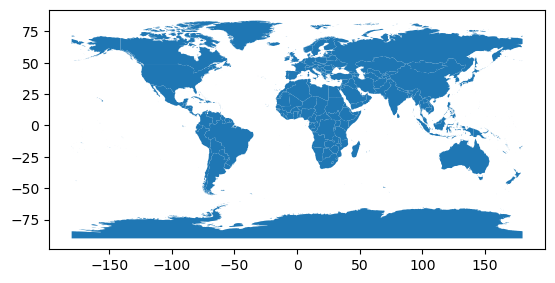

In [6]:
print(countries.crs)

In [7]:
# Verify the datasets have the same CRS
assert countries.crs == communities.crs

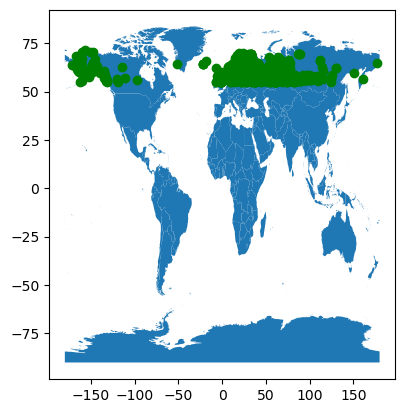

In [8]:
# plot the data

fig, ax = plt.subplots()

countries.plot(ax = ax)
communities.plot(ax = ax, color = 'green')

plt.show()


## Arctic commmunities by country

we want to calculate the number of Arctic communities by country



In [9]:
# Create a data frame with number of communities per country
n_comms = communities.groupby('country').size().reset_index(name = 'n_communities')

Merge the number of `n_comms` an `countries` data frame

to merge twow data frames they need to have at least one column in common
Do they have a column in common?

In [10]:
# to see if there are common columns between the two DFs
set(countries.columns).intersection(n_comms.columns)

set()

In [11]:
common_columns = set(countries.columns).intersection(n_comms.columns)

# Check if there are any common columns
if len(common_columns) != 0:
    print(f"Common columns: {common_columns}")
else: 
    print("No common columns")

No common columns


Check IN
make the previous code into a function called 'check_common_columns`, that takes in two data frames as arguments

In [12]:
def check_common_columns(df_1, df_2):
    common_columns = set(df_1.columns).intersection(df_2.columns)
    
    if len(common_columns) != 0:
        print(f"Common columns: {common_columns}")
    else: 
        print("No common columns")

check_common_columns(countries, n_comms)
    

No common columns


## Merge

we can use the `country_names` DF  to add the country names in `n_comms`

To merge the DFs we can use `pandas.merge()` function

```python
output_df = pd.merge(left_df, 
    right_df, 
    how = type_of_join, 
    on = column_to_join)

```

where

- `output_df` = df resulting from merge
- `left_df` = df we have "on the left side"
- `right_df` = df we have "on the right side"
- `how` = type of joing
- `by` = which column to join on, must be present on both DFs

In [13]:
n_comms = pd.merge(n_comms, country_names, how = 'left', on = 'country')

n_comms

,country,n_communities,admin
0,AX,1,Aland Islands
1,BY,8,Belarus
2,CA,7,Canada
3,DK,72,Denmark
4,EE,14,Estonia
5,FI,98,Finland
6,FO,1,Faroe Islands
7,GB,96,United Kingdom
8,GL,1,Greenland
9,IS,5,Iceland


In [14]:
check_common_columns(n_comms, countries)

Common columns: {'admin'}


In [17]:
# Check in 
arctic_countries = pd.merge(countries, n_comms, how = 'inner', on = 'admin')

arctic_countries

,admin,type,geometry,country,n_communities
0,United States of America,Country,"MULTIPOLYGON (((-132.74687 56.52568, -132.7576...",US,115
1,United Kingdom,Country,"MULTIPOLYGON (((-2.66768 51.62300, -2.74214 51...",GB,96
2,Sweden,Sovereign country,"MULTIPOLYGON (((19.07646 57.83594, 18.99375 57...",SE,133
3,Russia,Sovereign country,"MULTIPOLYGON (((145.88154 43.45952, 145.89561 ...",RU,774
4,Norway,Sovereign country,"MULTIPOLYGON (((20.62217 69.03687, 20.49199 69...",NO,48
5,Lithuania,Sovereign country,"MULTIPOLYGON (((20.95781 55.27891, 20.89980 55...",LT,26
6,Latvia,Sovereign country,"POLYGON ((26.59355 55.66753, 26.54287 55.67241...",LV,25
7,Iceland,Sovereign country,"POLYGON ((-15.54312 66.22852, -15.42847 66.224...",IS,5
8,Finland,Country,"MULTIPOLYGON (((24.15547 65.80527, 24.04902 65...",FI,98
9,Estonia,Sovereign country,"MULTIPOLYGON (((27.35195 57.52812, 27.32656 57...",EE,14


In [20]:
## Another way to do it 
# when merging spatial to non spatial DFs always make sure the geo spatial DF is on the left side or the geom will be dropped

arctic_countries = countries.merge(n_comms, how = 'inner', on = 'admin')

arctic_countries

,admin,type,geometry,country,n_communities
0,United States of America,Country,"MULTIPOLYGON (((-132.74687 56.52568, -132.7576...",US,115
1,United Kingdom,Country,"MULTIPOLYGON (((-2.66768 51.62300, -2.74214 51...",GB,96
2,Sweden,Sovereign country,"MULTIPOLYGON (((19.07646 57.83594, 18.99375 57...",SE,133
3,Russia,Sovereign country,"MULTIPOLYGON (((145.88154 43.45952, 145.89561 ...",RU,774
4,Norway,Sovereign country,"MULTIPOLYGON (((20.62217 69.03687, 20.49199 69...",NO,48
5,Lithuania,Sovereign country,"MULTIPOLYGON (((20.95781 55.27891, 20.89980 55...",LT,26
6,Latvia,Sovereign country,"POLYGON ((26.59355 55.66753, 26.54287 55.67241...",LV,25
7,Iceland,Sovereign country,"POLYGON ((-15.54312 66.22852, -15.42847 66.224...",IS,5
8,Finland,Country,"MULTIPOLYGON (((24.15547 65.80527, 24.04902 65...",FI,98
9,Estonia,Sovereign country,"MULTIPOLYGON (((27.35195 57.52812, 27.32656 57...",EE,14


# when merging spatial to non spatial DFs always make sure the geo spatial DF is on the left side or the geom will be dropped


### Review results

In [ ]:
print(f"Countries in n_comms: {len(n_comms)}")
print(f"Countries in arctic_countries: {len(arctic_countries)}")

In [21]:
# Countries in n_comms without a match in countries
n_comms[~n_comms['admin'].isin(countries['admin'])]

,country,n_communities,admin
0,AX,1,Aland Islands


In [22]:
countries[countries['admin'].str.contains('Aland')]

,admin,type,geometry
168,Aland,Country,"MULTIPOLYGON (((19.98955 60.35117, 20.02021 60..."


In [23]:
# match the name used in the countries data
n_comms['admin'] = n_comms['admin'].replace('Aland Islands', 'Aland')

# Merge again
arctic_countries = countries.merge(n_comms, how = 'inner', on = 'admin')

print(f"Countries in arctic_countries: {len(arctic_countries)}")

Countries in arctic_countries: 16


<Axes: >

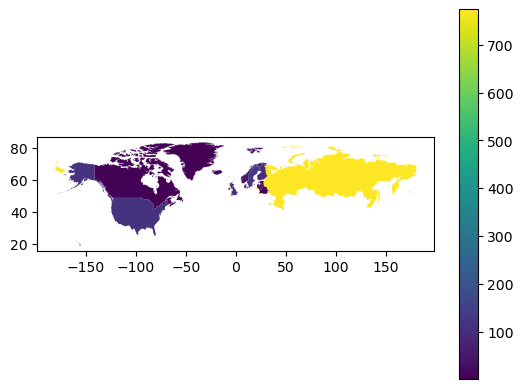

In [25]:
arctic_countries.plot(column = 'n_communities',  # Indicates which column to color by
                      legend = True)

## Reprojecting 

In [26]:
# reproject to CRS optimized for Arctic region
arctic_countries = arctic_countries.to_crs('epsg:3413')

In [27]:
arctic_countries.crs

<Projected CRS: EPSG:3413>
Name: WGS 84 / NSIDC Sea Ice Polar Stereographic North
Axis Info [cartesian]:
- X[south]: Easting (metre)
- Y[south]: Northing (metre)
Area of Use:
- name: Northern hemisphere - north of 60°N onshore and offshore, including Arctic.
- bounds: (-180.0, 60.0, 180.0, 90.0)
Coordinate Operation:
- name: US NSIDC Sea Ice polar stereographic north
- method: Polar Stereographic (variant B)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

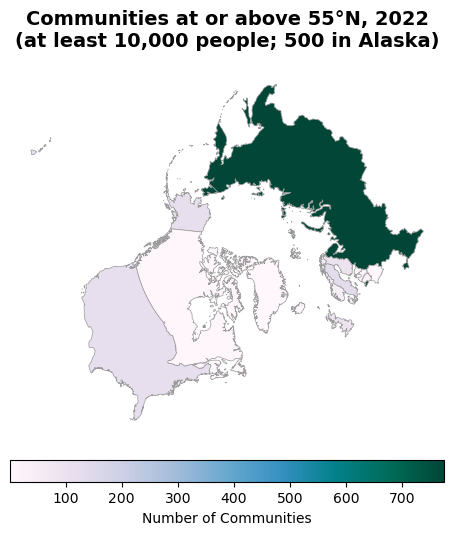

In [30]:
fig, ax = plt.subplots(figsize=(8, 6))

# Remove the axis for a cleaner map
ax.axis('off')

# Create choropleth map of communities
# Plot with refined color and edge style
arctic_countries.plot(
    ax=ax,
    column='n_communities',
    cmap='PuBuGn',
    legend=True,
    edgecolor="0.6",
    linewidth=0.5,
    legend_kwds={
        "shrink": 0.7,
        "label": "Number of Communities",
        "orientation": "horizontal",
        "pad": 0.05
    }
)

# Add title for better context
ax.set_title('Communities at or above 55°N, 2022\n(at least 10,000 people; 500 in Alaska)',
             fontsize=14, weight='bold', pad=15)

plt.show()